<a href="https://colab.research.google.com/github/Kevin911212/CLIP-project/blob/main/CNN(flowers_102).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN(ResNet-50)

In [ ]:
pip install torchvision timm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 104.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 93.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 54.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitli

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import Flowers102
from torch.utils.data import DataLoader, random_split

# === 轉換設定（與 ResNet-50 相容）===
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],  # ImageNet mean/std
                         std=[0.229, 0.224, 0.225])
])

# === 載入訓練與測試資料 ===
trainset = Flowers102(root='./data', split='train', transform=transform, download=True)
valset = Flowers102(root='./data', split='val', transform=transform, download=True)
testset = Flowers102(root='./data', split='test', transform=transform, download=True)

trainloader = DataLoader(trainset, batch_size=32, shuffle=True)
valloader = DataLoader(valset, batch_size=32, shuffle=False)
testloader = DataLoader(testset, batch_size=32, shuffle=False)


100%|██████████| 345M/345M [00:13<00:00, 25.0MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.71MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 8.97MB/s]


In [ ]:
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet50

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# === 預訓練模型 ===
model = resnet50(pretrained=True)
model.fc = nn.Linear(2048, 102)  # Flower102 的類別數
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 138MB/s]


In [ ]:
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []


Epoch [1/10]: 100%|██████████| 32/32 [00:20<00:00,  1.53it/s, loss=3.75]


[Epoch 1] Train Loss: 4.1474 | Train Acc: 0.1941 | Val Loss: 2.9990 | Val Acc: 0.5127


Epoch [2/10]: 100%|██████████| 32/32 [00:14<00:00,  2.17it/s, loss=1.5]


[Epoch 2] Train Loss: 2.3958 | Train Acc: 0.7892 | Val Loss: 1.9532 | Val Acc: 0.7402


Epoch [3/10]: 100%|██████████| 32/32 [00:14<00:00,  2.16it/s, loss=0.832]


[Epoch 3] Train Loss: 1.2418 | Train Acc: 0.9235 | Val Loss: 1.2243 | Val Acc: 0.8402


... (10 outputs left out)

Epoch [9/10]: 100%|██████████| 32/32 [00:14<00:00,  2.13it/s, loss=0.0496]


[Epoch 9] Train Loss: 0.0390 | Train Acc: 1.0000 | Val Loss: 0.4492 | Val Acc: 0.9137


Epoch [10/10]: 100%|██████████| 32/32 [00:14<00:00,  2.14it/s, loss=0.0259]


[Epoch 10] Train Loss: 0.0296 | Train Acc: 1.0000 | Val Loss: 0.4235 | Val Acc: 0.9147


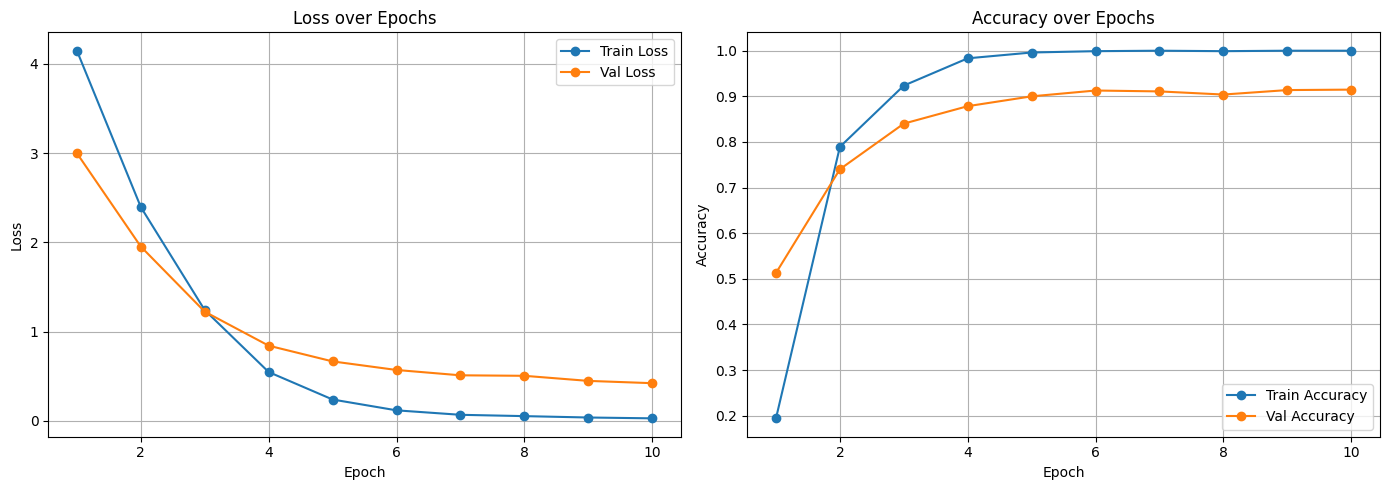

In [ ]:
from tqdm import tqdm
import matplotlib.pyplot as plt

# === 評估函式 ===
def evaluate(model, dataloader, criterion):
    model.eval()
    correct, total = 0, 0
    running_loss = 0.0
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            predicted = outputs.argmax(1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return running_loss / len(dataloader), correct / total

# === 儲存用 ===
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

# === 訓練迴圈 ===
num_epochs = 10
for epoch in range(num_epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    loop = tqdm(trainloader, desc=f"Epoch [{epoch+1}/{num_epochs}]")

    for inputs, labels in loop:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predicted = outputs.argmax(1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        loop.set_postfix(loss=loss.item())

    train_loss = running_loss / len(trainloader)
    train_acc = correct / total
    val_loss, val_acc = evaluate(model, valloader, criterion)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"[Epoch {epoch+1}] Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# === 畫圖 ===
epochs = range(1, num_epochs + 1)
plt.figure(figsize=(14, 5))

# Loss 曲線
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss', marker='o')
plt.plot(epochs, val_losses, label='Val Loss', marker='o')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy 曲線
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label='Train Accuracy', marker='o')
plt.plot(epochs, val_accuracies, label='Val Accuracy', marker='o')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# Flowers102 類別名稱
flower102_classes = [
    'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold',
    'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle',
    'snapdragon', "colt's foot", 'king protea', 'spear thistle', 'yellow iris',
    'globe flower', 'purple coneflower', 'peruvian lily', 'balloon flower', 'giant white arum lily',
    'fire lily', 'pincushion flower', 'fritillary', 'red ginger', 'grape hyacinth',
    'corn poppy', 'prince of wales feathers', 'stemless gentian', 'sweet william', 'carnation',
    'garden phlox', 'love in the mist', 'mexican aster', 'alpine sea holly', 'ruby-lipped cattleya',
    'cape flower', 'great masterwort', 'siam tulip', 'lenten rose', 'barbeton daisy',
    'daffodil', 'sword lily', 'poinsettia', 'bolero deep blue', 'wallflower',
    'marigold', 'buttercup', 'oxeye daisy', 'common dandelion', 'petunia',
    'wild pansy', 'primula', 'sunflower', 'pelargonium', 'bishop of llandaff',
    'gaura', 'geranium', 'orange dahlia', 'pink-yellow dahlia', 'cautleya spicata',
    'japanese anemone', 'black-eyed susan', 'silverbush', 'californian poppy', 'osteospermum',
    'spring crocus', 'bearded iris', 'windflower', 'tree poppy', 'gazania',
    'azalea', 'water lily', 'rose', 'thorn apple', 'morning glory',
    'passion flower', 'lotus', 'toad lily', 'anthurium', 'frangipani',
    'clematis', 'hibiscus', 'columbine', 'desert-rose', 'tree mallow',
    'magnolia', 'cyclamen ', 'watercress', 'canna lily', 'hippeastrum ',
    'bee balm', 'pink quill', 'foxglove', 'bougainvillea', 'camellia',
    'mallow', 'mexican petunia', 'bromelia', 'blanket flower', 'trumpet creeper',
    'blackberry lily'
]


✅ Final Test Accuracy: 0.8932



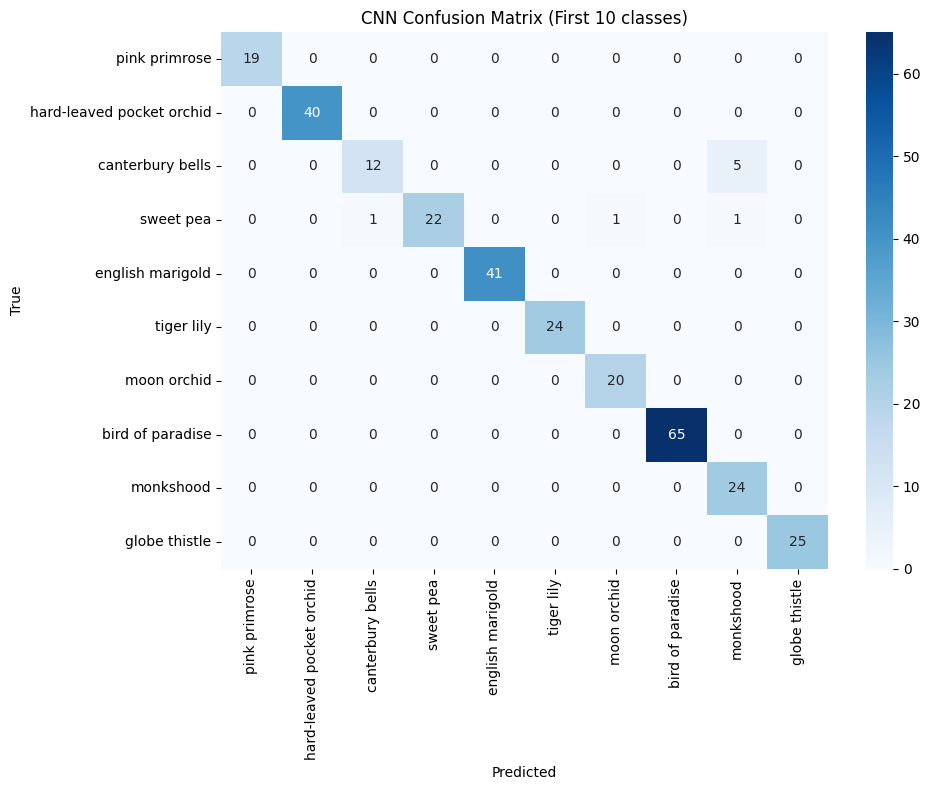


[Classification Report (First 10 classes)]
                           precision    recall  f1-score   support

            pink primrose     0.5588    0.9500    0.7037        20
hard-leaved pocket orchid     0.9302    1.0000    0.9639        40
         canterbury bells     0.5217    0.6000    0.5581        20
                sweet pea     0.5946    0.6111    0.6027        36
         english marigold     0.9762    0.9111    0.9425        45
               tiger lily     1.0000    0.9600    0.9796        25
              moon orchid     0.9524    1.0000    0.9756        20
         bird of paradise     0.9848    1.0000    0.9924        65
                monkshood     0.6486    0.9231    0.7619        26
            globe thistle     1.0000    1.0000    1.0000        25

                micro avg     0.8295    0.9068    0.8665       322
                macro avg     0.8167    0.8955    0.8480       322
             weighted avg     0.8512    0.9068    0.8734       322



In [ ]:
import torch
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 驗證階段收集所有預測和標籤
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 計算整體準確率
acc = (all_preds == all_labels).mean()
print(f"\n✅ Final Test Accuracy: {acc:.4f}\n")

# 只顯示前10類
top_k = 10
labels_to_show = np.arange(top_k)
class_names_to_show = flower102_classes[:top_k]

# 計算混淆矩陣（只含前10類）
cm = confusion_matrix(all_labels, all_preds, labels=labels_to_show)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names_to_show, yticklabels=class_names_to_show)
plt.title("CNN Confusion Matrix (First 10 classes)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# 輸出前10類的分類報告
print("\n[Classification Report (First 10 classes)]")
print(classification_report(all_labels, all_preds,
                            labels=labels_to_show,
                            target_names=class_names_to_show,
                            digits=4))
